# Figures of the article

Draws every plot and schematic of the article with matplotlib and writes it to `out/`.
`run_all.py` copies the PDFs to `../../paper/figures/`, where LaTeX includes them at
their natural size.

**Input.** `plot_data.csv` in this folder, written by `../analysis.py`. One row per plotted
value, columns `figure, series, label, x, y, c, flag`:

| figure | series | label | x | y | c | flag |
|---|---|---|---|---|---|---|
| `f1_quantiles` | setting | quantile name | | F1 | | |
| `precision_recall` | setting | decile | recall | precision | | |
| `feasibility` | parameter | | grid level | share (%) | count | |
| `parameter_contrast` | setting | parameter | | Cliff's delta | | 1 = significant |
| `top_decile` | B | run id | path length (m) | F1 | HD95 (m) | 1 = non-dominated |
| `length_model` | | run id | nominal length (m) | recorded length (m) | | |
| `candidates` | B | run id | path length (m) | F1 | HD95 (m) | |

The two schematics (scan patch, pipeline) are drawn from the equations and need no data.
The qualitative figure arranges the four images in `qualitative/`.

**Type size rule.** Body text of the article is 10 pt. All text in all figures is
`BODY_PT - 2 = 8 pt`: axis labels, tick labels, legends, annotations, colour-bar labels
and panel letters. Figures are written at the exact column width (252 pt) or text width
(516 pt) and are never rescaled in LaTeX, so 8 pt in the file is 8 pt on the page.
`save()` refuses to write a figure that contains text of any other size. Subscripts
inside mathematical symbols (the "xy" in $r_{xy}$) are set smaller by the math
typesetter, exactly as in the body text; they are the only exception.

In [1]:
import csv
from collections import defaultdict
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.text import Text
from mpl_toolkits.mplot3d import proj3d

HERE = Path.cwd()
OUT = HERE / "out"
OUT.mkdir(exist_ok=True)

BODY_PT = 10.0               # body text of the article
FONT_PT = BODY_PT - 2.0      # every piece of text in every figure
COL_PT, TEXT_PT = 252.0, 516.0          # IEEE column and text width in TeX points
COL, TEXT = COL_PT / 72.27, TEXT_PT / 72.27
PANEL = 0.485 * TEXT                     # one of two panels side by side

plt.rcParams.update({
    "font.size": FONT_PT, "axes.labelsize": FONT_PT, "axes.titlesize": FONT_PT,
    "xtick.labelsize": FONT_PT, "ytick.labelsize": FONT_PT, "legend.fontsize": FONT_PT,
    "legend.title_fontsize": FONT_PT, "figure.titlesize": FONT_PT,
    # Times, as in the body text of the article; STIX is the fallback that ships with matplotlib
    "font.family": "serif", "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral"],
    "mathtext.fontset": "stix", "axes.unicode_minus": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 400,
    "axes.linewidth": .6, "xtick.major.width": .6, "ytick.major.width": .6,
    "xtick.major.size": 2.4, "ytick.major.size": 2.4, "grid.linewidth": .4, "grid.color": "#DDDDDD",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

COLOR = {"S": "#4C72B0", "I": "#DD8452", "G": "#55A868", "B": "#C44E52"}
NAME = {"S": "Simple", "I": "InitialAlign", "G": "GlobalAnchor", "B": "Both"}
MARK = {"S": "o", "I": "s", "G": "^", "B": "D"}

DATA = defaultdict(list)
with (HERE / "plot_data.csv").open(newline="", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        for key in ("x", "y", "c"):
            row[key] = float(row[key]) if row[key] != "" else None
        DATA[row["figure"]].append(row)

FONT_REPORT = []


def save(fig, name, width_pt):
    # Checks the type size of every text in the figure, then writes PDF and PNG.
    fig.canvas.draw()
    sizes = sorted({round(t.get_fontsize(), 2) for t in fig.findobj(Text)
                    if t.get_visible() and t.get_text().strip()})
    width = round(fig.get_figwidth() * 72.27, 1)
    ok = sizes == [FONT_PT] and abs(width - width_pt) < 0.2
    FONT_REPORT.append({"figure": name, "text_sizes_pt": sizes, "width_pt": width, "ok": ok})
    if not ok:
        raise ValueError(f"{name}: text sizes {sizes} pt, width {width} pt; required {FONT_PT} pt and {width_pt} pt")
    fig.savefig(OUT / f"{name}.pdf")
    fig.savefig(OUT / f"{name}.png")
    plt.show()

## Fig. 1(a): scan patch on the ellipsoid (schematic)

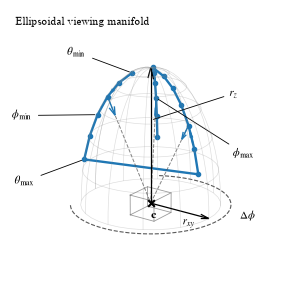

In [2]:
r, z = .22, .50
tt, pp = np.meshgrid(np.linspace(0, np.pi / 2, 19), np.linspace(-np.pi, np.pi, 37))
fig = plt.figure(figsize=(PANEL, 2.74))
ax = fig.add_axes([0, 0, 1, 1], projection="3d")
ax.plot_wireframe(r * np.sin(tt) * np.cos(pp), r * np.sin(tt) * np.sin(pp), z * np.cos(tt),
                  rstride=3, cstride=3, linewidth=.45, alpha=.30, color="0.55")
path = []
angles = np.deg2rad([-140, -10, 120])
for i, p in enumerate(angles):
    t = np.deg2rad(np.linspace(15, 70, 6))
    if i % 2:
        t = t[::-1]
    path.extend(np.column_stack([r * np.sin(t) * np.cos(p), r * np.sin(t) * np.sin(p), z * np.cos(t)]))
path = np.array(path)
ax.plot(*path.T, "-o", linewidth=1.7, markersize=3)
for i in (1, 7, 13):
    v = path[i + 1] - path[i]
    ax.quiver(*(path[i] + .25 * v), *(v * .45), arrow_length_ratio=.5, linewidth=1.2)
for i in (2, 8, 15):
    ax.plot([path[i, 0], 0], [path[i, 1], 0], [path[i, 2], 0], linestyle="--", linewidth=.7, alpha=.75, color="0.35")
    ax.quiver(*path[i], *(-path[i] * .17), arrow_length_ratio=.45, linewidth=1)
ax.scatter([0], [0], [0], s=23, marker="x", color="black")
ax.text(.012, -.018, -.050, r"$\mathbf{c}$")
ax.quiver(0, 0, 0, 0, 0, z, arrow_length_ratio=.08, linewidth=.9, color="black")
ax.quiver(0, 0, 0, .22, 0, 0, arrow_length_ratio=.14, linewidth=.9, color="black")
ax.text(.135, -.018, -.038, r"$r_{xy}$")
arc = np.linspace(angles[0], angles[-1], 100)
ax.plot(.252 * np.cos(arc), .252 * np.sin(arc), np.zeros_like(arc), linestyle="--", linewidth=.8, color="0.35")
ax.text(.285, .075, -.012, r"$\Delta\phi$")
a, lo, hi = .046, -.04, .035          # schematic keep-out volume, illustrative size
for x in (-a, a):
    for y in (-a, a):
        ax.plot([x, x], [y, y], [lo, hi], linewidth=.6, alpha=.7, color="0.45")
for h in (lo, hi):
    ax.plot([-a, a, a, -a, -a], [-a, -a, a, a, -a], [h] * 5, linewidth=.6, alpha=.7, color="0.45")
ax.set_box_aspect((.70, .70, .68)); ax.view_init(elev=19, azim=-54)
ax.set_xlim(-.255, .255); ax.set_ylim(-.255, .255); ax.set_zlim(-.055, .505)
ax.set_axis_off()
ax.text2D(.02, .975, "Ellipsoidal viewing manifold", transform=ax.transAxes, va="top")
for label, position, location in [("$r_z$", [0, 0, .31], (.815, .695)),
                                  (r"$\theta_{\min}$", path[0], (.245, .845)),
                                  (r"$\theta_{\max}$", path[5], (.055, .375)),
                                  (r"$\phi_{\min}$", path[3], (.045, .615)),
                                  (r"$\phi_{\max}$", path[-3], (.855, .475))]:
    x2, y2, _ = proj3d.proj_transform(*position, ax.get_proj())
    ax.annotate(label, (x2, y2), xytext=location, textcoords="axes fraction",
                ha="center", va="center", arrowprops={"arrowstyle": "-", "lw": .6})
save(fig, "ellipsoid", 0.485 * TEXT_PT)

## Fig. 1(b): processing stages (schematic)

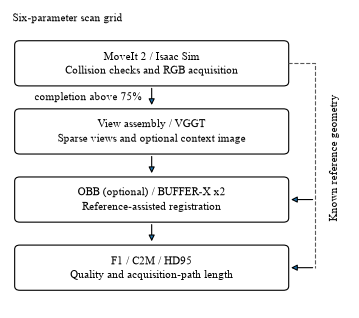

In [3]:
fig = plt.figure(figsize=(PANEL, 3.05))
ax = fig.add_axes([.01, .01, .98, .98]); ax.set_xlim(0, 4); ax.set_ylim(0, 4.30); ax.axis("off")
levels = [3.22, 2.24, 1.26, .28]
labels = ["MoveIt 2 / Isaac Sim\nCollision checks and RGB acquisition",
          "View assembly / VGGT\nSparse views and optional context image",
          "OBB (optional) / BUFFER-X x2\nReference-assisted registration",
          "F1 / C2M / HD95\nQuality and acquisition-path length"]
for y, label in zip(levels, labels):
    ax.add_patch(FancyBboxPatch((.08, y), 3.18, .60, boxstyle="round,pad=.025,rounding_size=.06",
                                fill=False, linewidth=.8))
    ax.text(1.67, y + .30, label, ha="center", va="center", linespacing=1.45)
for upper, lower in zip(levels[:-1], levels[1:]):
    ax.add_patch(FancyArrowPatch((1.67, upper - .02), (1.67, lower + .64), arrowstyle="-|>",
                                 mutation_scale=9, linewidth=.8))
ax.text(1.55, 3.03, "completion above 75%", ha="right", va="center")
ax.text(.03, 4.24, "Six-parameter scan grid", va="top")
ax.plot([3.28, 3.60, 3.60], [3.52, 3.52, .58], linewidth=.8, linestyle="--", color="0.35")
for y in (1.56, .58):
    ax.add_patch(FancyArrowPatch((3.60, y), (3.28, y), arrowstyle="-|>", mutation_scale=9, linewidth=.8))
ax.text(3.82, 2.16, "Known reference geometry", rotation=90, ha="center", va="center")
save(fig, "pipeline", 0.485 * TEXT_PT)

## Share of grid configurations per parameter level

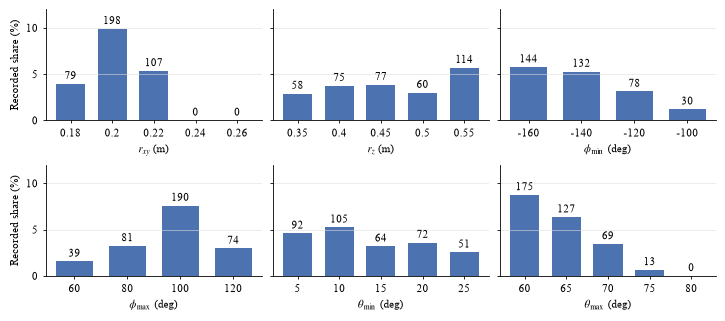

In [4]:
LABEL = {"radius_xy": r"$r_{xy}$ (m)", "radius_z": r"$r_z$ (m)", "azimuth_start": r"$\phi_{\min}$ (deg)",
         "azimuth_end": r"$\phi_{\max}$ (deg)", "elevation_min": r"$\theta_{\min}$ (deg)",
         "elevation_max": r"$\theta_{\max}$ (deg)"}
fig, axes = plt.subplots(2, 3, figsize=(TEXT, 3.1), constrained_layout=True, sharey=True)
for ax, key in zip(axes.flat, LABEL):
    rows = [d for d in DATA["feasibility"] if d["series"] == key]
    x = np.arange(len(rows))
    ax.bar(x, [d["y"] for d in rows], color=COLOR["S"], width=.7)
    for xi, d in zip(x, rows):
        ax.text(xi, d["y"] + .25, f'{d["c"]:.0f}', ha="center", va="bottom")
    ax.set_xticks(x, [f'{d["x"]:g}' for d in rows]); ax.set_xlabel(LABEL[key]); ax.grid(axis="y")
    ax.set_ylim(0, 12)
for ax in axes[:, 0]:
    ax.set_ylabel("Recorded share (%)")
save(fig, "feasibility", TEXT_PT)

## F1 quantiles per setting

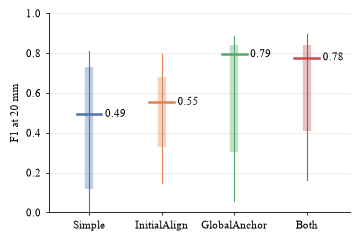

In [5]:
fig, ax = plt.subplots(figsize=(COL, 2.3), constrained_layout=True)
for i, s in enumerate("SIGB"):
    q = {d["label"]: d["y"] for d in DATA["f1_quantiles"] if d["series"] == s}
    ax.plot([i, i], [q["p10"], q["p90"]], color=COLOR[s], lw=6, alpha=.35, solid_capstyle="butt")
    ax.plot([i, i], [q["min"], q["max"]], color=COLOR[s], lw=.8)
    ax.plot([i - .17, i + .17], [q["p50_mid"]] * 2, color=COLOR[s], lw=1.8)
    ax.text(i + .22, q["p50_mid"], f'{q["p50_mid"]:.2f}', va="center")
ax.set_xticks(range(4), [NAME[s] for s in "SIGB"])
ax.set_xlim(-.55, 3.6); ax.set_ylim(0, 1); ax.set_ylabel("F1 at 20 mm"); ax.grid(axis="y")
save(fig, "f1_quantiles", COL_PT)

## Precision and recall of the three F1 deciles

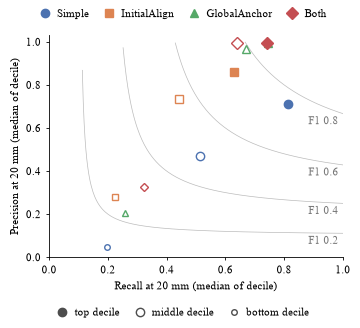

In [6]:
fig, ax = plt.subplots(figsize=(COL, 3.2), constrained_layout=True)
SIZE = {"top": 6, "middle": 6, "bottom": 4}
for d in DATA["precision_recall"]:
    s = d["series"]
    ax.plot(d["x"], d["y"], MARK[s], ms=SIZE[d["label"]], mec=COLOR[s], mew=1,
            mfc=COLOR[s] if d["label"] == "top" else "white")
for f in (0.2, 0.4, 0.6, 0.8):
    x = np.linspace(f / 2 + 1e-3, 1, 300); y = f * x / (2 * x - f)
    ax.plot(x[y <= 1], y[y <= 1], color="#BBBBBB", lw=.5, zorder=0)
    ax.text(.985, f / (2 - f) - .012, f"F1 {f:.1f}", color="#777777", ha="right", va="top")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.03)
ax.set_xlabel("Recall at 20 mm (median of decile)"); ax.set_ylabel("Precision at 20 mm (median of decile)")
settings = [Line2D([], [], ls="none", marker=MARK[s], color=COLOR[s], ms=6, label=NAME[s]) for s in "SIGB"]
deciles = [Line2D([], [], ls="none", marker="o", mec="0.3", mfc="0.3", ms=6, label="top decile"),
           Line2D([], [], ls="none", marker="o", mec="0.3", mfc="white", ms=6, label="middle decile"),
           Line2D([], [], ls="none", marker="o", mec="0.3", mfc="white", ms=4, label="bottom decile")]
fig.legend(handles=settings, loc="outside upper center", ncol=4, columnspacing=.8, handletextpad=.1)
fig.legend(handles=deciles, loc="outside lower center", ncol=3, columnspacing=.8, handletextpad=.1)
save(fig, "precision_recall", COL_PT)

## Scan parameters of the top and bottom decile (Cliff's delta)

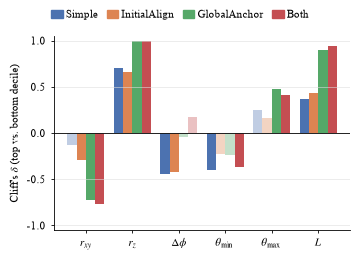

In [7]:
PARAMS = ["radius_xy", "radius_z", "azimuth_span", "elevation_min", "elevation_max", "path_length_m"]
TICKS = [r"$r_{xy}$", r"$r_z$", r"$\Delta\phi$", r"$\theta_{\min}$", r"$\theta_{\max}$", r"$L$"]
fig, ax = plt.subplots(figsize=(COL, 2.5), constrained_layout=True)
w = .2
for j, s in enumerate("SIGB"):
    rows = {d["label"]: d for d in DATA["parameter_contrast"] if d["series"] == s}
    x = np.arange(len(PARAMS)) + (j - 1.5) * w
    for xi, p in zip(x, PARAMS):
        ax.bar(xi, rows[p]["y"], w, color=COLOR[s], alpha=1 if rows[p]["flag"] == "1" else .35)
ax.axhline(0, color="black", lw=.6)
ax.set_xticks(range(len(PARAMS)), TICKS); ax.set_ylim(-1.05, 1.05); ax.grid(axis="y")
ax.set_ylabel("Cliff's $\\delta$ (top vs. bottom decile)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR[s], label=NAME[s]) for s in "SIGB"],
           loc="outside upper center", ncol=4, columnspacing=.8, handlelength=1, handletextpad=.3)
save(fig, "parameter_contrast", COL_PT)

## Recorded against nominal path length

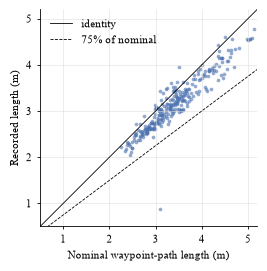

In [8]:
rows = DATA["length_model"]
fig, ax = plt.subplots(figsize=(COL, 2.6), constrained_layout=True)
ax.scatter([d["x"] for d in rows], [d["y"] for d in rows], s=7, color=COLOR["S"], alpha=.6, linewidth=0)
lim = [0.5, 5.2]
ax.plot(lim, lim, color="black", lw=.6, label="identity")
ax.plot(lim, [.75 * v for v in lim], color="black", lw=.6, ls="--", label="75% of nominal")
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal"); ax.grid(True)
ax.set_xlabel("Nominal waypoint-path length (m)"); ax.set_ylabel("Recorded length (m)")
ax.legend(loc="upper left")
save(fig, "length_model", COL_PT)

## Top F1 decile of setting Both

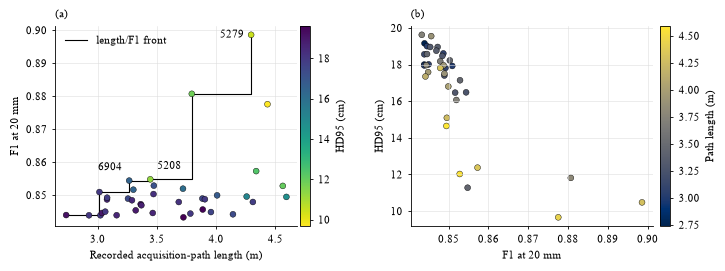

In [9]:
rows = DATA["top_decile"]
L, F, H = (np.array([d[k] for d in rows]) for k in ("x", "y", "c"))
front = np.array([d["flag"] == "1" for d in rows])
fig, (a, b) = plt.subplots(1, 2, figsize=(TEXT, 2.6), constrained_layout=True)
fig.get_layout_engine().set(wspace=.08)
sc = a.scatter(L, F, c=H * 100, cmap="viridis_r", s=18, edgecolor="black", linewidth=.3, zorder=3)
order = np.argsort(L[front])
a.step(L[front][order], F[front][order], where="post", color="black", lw=.8, zorder=2, label="length/F1 front")
ids = [d["label"] for d in rows]
for rid, dx, dy, ha in (("grid_run_6904", -.06, .004, "right"), ("grid_run_5208", .06, .004, "left"),
                        ("grid_run_5279", -.06, 0, "right")):
    i = ids.index(rid)
    a.annotate(rid[-4:], (L[i], F[i]), (L[i] + dx, F[i] + dy), ha=ha, va="center")
a.set_xlabel("Recorded acquisition-path length (m)"); a.set_ylabel("F1 at 20 mm"); a.grid(True)
a.legend(loc="upper left"); a.set_title("(a)", loc="left")
fig.colorbar(sc, ax=a, label="HD95 (cm)", pad=.01)
sc2 = b.scatter(F, H * 100, c=L, cmap="cividis", s=18, edgecolor="black", linewidth=.3)
b.set_xlabel("F1 at 20 mm"); b.set_ylabel("HD95 (cm)"); b.grid(True); b.set_title("(b)", loc="left")
fig.colorbar(sc2, ax=b, label="Path length (m)", pad=.01)
save(fig, "top_decile", TEXT_PT)

## Eleven archived operating points

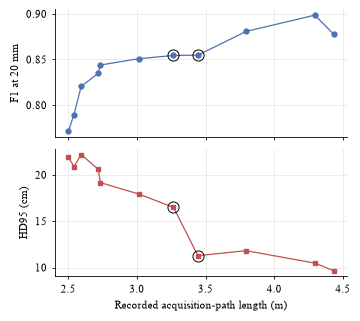

In [10]:
rows = sorted(DATA["candidates"], key=lambda d: d["x"])
L, F, H = (np.array([d[k] for d in rows]) for k in ("x", "y", "c"))
ids = [d["label"] for d in rows]
fig, (a, b) = plt.subplots(2, 1, figsize=(COL, 3.1), constrained_layout=True, sharex=True)
a.plot(L, F, "-o", color=COLOR["S"], ms=3.5, lw=.9); a.set_ylabel("F1 at 20 mm"); a.grid(True)
b.plot(L, H * 100, "-s", color=COLOR["B"], ms=3.5, lw=.9); b.set_ylabel("HD95 (cm)"); b.grid(True)
b.set_xlabel("Recorded acquisition-path length (m)")
for ax, y in ((a, F), (b, H * 100)):
    for rid in ("grid_run_6904", "grid_run_5208"):
        i = ids.index(rid)
        ax.plot(L[i], y[i], "o", ms=8, mfc="none", mec="black", mew=.7)
save(fig, "candidates", COL_PT)

## Registered reconstructions, one per setting (image montage)

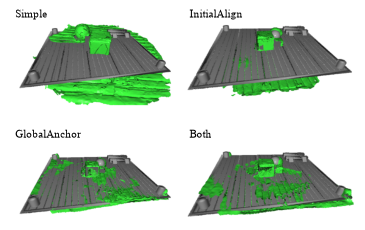

In [11]:
panels = [("qual_simple.png", "Simple"), ("qual_initial.png", "InitialAlign"),
          ("qual_global.png", "GlobalAnchor"), ("qual_both.png", "Both")]
fig = plt.figure(figsize=(COL, 2.38))
for index, (filename, label) in enumerate(panels):
    column, row = index % 2, index // 2
    ax = fig.add_axes([.005 + column * .5, .525 - row * .505, .49, .425])
    ax.imshow(mpimg.imread(str(HERE / "qualitative" / filename)), interpolation="antialiased")
    ax.set_axis_off()
    fig.text(.02 + column * .5, .965 - row * .505, label, ha="left", va="top")
save(fig, "qualitative", COL_PT)

## Type-size report

In [12]:
with (OUT / "font_report.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(FONT_REPORT[0]))
    writer.writeheader(); writer.writerows(FONT_REPORT)
print(f"body text {BODY_PT:g} pt, required figure text {FONT_PT:g} pt")
for r in FONT_REPORT:
    print(f'{r["figure"]:20s} text sizes {r["text_sizes_pt"]} pt   width {r["width_pt"]} pt   {"OK" if r["ok"] else "FAIL"}')
assert all(r["ok"] for r in FONT_REPORT) and len(FONT_REPORT) == 10

body text 10 pt, required figure text 8 pt
ellipsoid            text sizes [8.0] pt   width 250.3 pt   OK
pipeline             text sizes [8.0] pt   width 250.3 pt   OK
feasibility          text sizes [8.0] pt   width 516.0 pt   OK
f1_quantiles         text sizes [8.0] pt   width 252.0 pt   OK
precision_recall     text sizes [8.0] pt   width 252.0 pt   OK
parameter_contrast   text sizes [8.0] pt   width 252.0 pt   OK
length_model         text sizes [8.0] pt   width 252.0 pt   OK
top_decile           text sizes [8.0] pt   width 516.0 pt   OK
candidates           text sizes [8.0] pt   width 252.0 pt   OK
qualitative          text sizes [8.0] pt   width 252.0 pt   OK
